## Load Forecast vs. rtm price correlation

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DATA_ROOT = Path('../..').resolve() / "01_data"
LOAD_FORECAST = PROJECT_DATA_ROOT / "2_cleaned" / "load" / "forecast" / "Hourly ERCOT system load and prediction 20220201 20251201.csv"
RTM_PRICE = PROJECT_DATA_ROOT / "2_cleaned" / "rtm_price" / "rtm_price_aggregated_2021_2025.csv"
OUT_DIR = PROJECT_DATA_ROOT / "3_analysis" / "load_forecast"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df_rtm = pd.read_csv(RTM_PRICE)
df_load = pd.read_csv(LOAD_FORECAST)
df_load.rename(columns={'actual_ERCOT': 'actual_load', 'error_ERCOT': 'load_forecast_error'}, inplace=True)
df_rtm

,date_time,avg_rtm_price,std_rtm_price
0,2021-01-01 01:00:00,18.173500,7.122839
1,2021-01-01 02:00:00,20.960833,22.277422
2,2021-01-01 03:00:00,20.779667,25.741755
3,2021-01-01 04:00:00,16.416667,2.188030
4,2021-01-01 05:00:00,18.075333,4.399391
...,...,...,...
43814,2025-12-31 20:00:00,55.840833,0.001543
43815,2025-12-31 21:00:00,31.055000,0.000000
43816,2025-12-31 22:00:00,24.260333,0.275634
43817,2025-12-31 23:00:00,20.272500,0.000000


In [3]:
# merge
df_load['datetime'] = pd.to_datetime(df_load['datetime'])
df_rtm['date_time'] = pd.to_datetime(df_rtm['date_time'])
df = df_rtm.merge(df_load, left_on='date_time', right_on='datetime', how='inner')
df = df.drop(columns=['date_time', 'std_rtm_price'])
df

,avg_rtm_price,datetime,actual_load,load_forecast_error
0,1.422167,2022-02-01 01:00:00,35709.832031,-561.832031
1,0.536667,2022-02-01 02:00:00,34733.136719,-679.136719
2,1.695167,2022-02-01 03:00:00,34448.484375,-946.484375
3,3.226833,2022-02-01 04:00:00,34471.617188,-837.617188
4,3.926333,2022-02-01 05:00:00,35127.335938,-571.335938
...,...,...,...,...
33670,90.263333,2025-11-30 20:00:00,55294.851563,-1311.851563
33671,102.712167,2025-11-30 21:00:00,54523.589844,-36.589844
33672,94.015500,2025-11-30 22:00:00,53437.218750,1104.781250
33673,78.837000,2025-11-30 23:00:00,51638.382813,2117.617187


In [4]:
# error in absolute value
df['abs_load_error'] = abs(df['load_forecast_error'])
df

,avg_rtm_price,datetime,actual_load,load_forecast_error,abs_load_error
0,1.422167,2022-02-01 01:00:00,35709.832031,-561.832031,561.832031
1,0.536667,2022-02-01 02:00:00,34733.136719,-679.136719,679.136719
2,1.695167,2022-02-01 03:00:00,34448.484375,-946.484375,946.484375
3,3.226833,2022-02-01 04:00:00,34471.617188,-837.617188,837.617188
4,3.926333,2022-02-01 05:00:00,35127.335938,-571.335938,571.335938
...,...,...,...,...,...
33670,90.263333,2025-11-30 20:00:00,55294.851563,-1311.851563,1311.851563
33671,102.712167,2025-11-30 21:00:00,54523.589844,-36.589844,36.589844
33672,94.015500,2025-11-30 22:00:00,53437.218750,1104.781250,1104.781250
33673,78.837000,2025-11-30 23:00:00,51638.382813,2117.617187,2117.617187


/usr/local/lib/python3.10/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.10/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Text(0.5, 0, 'Load Prediction Error')

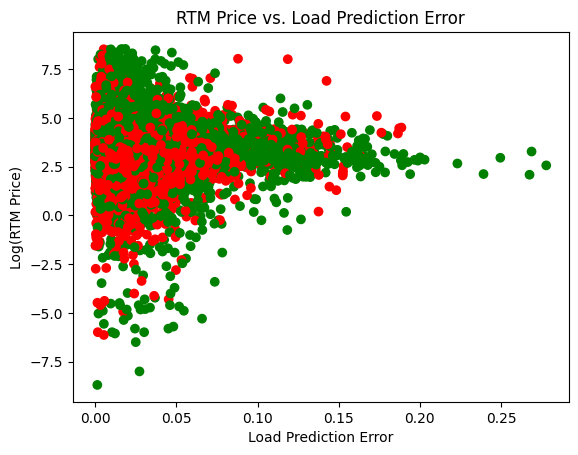

In [5]:
# investigate negative + positive predictions
# error = predicted - actual 

colors = np.where(df['load_forecast_error'] >= 0, 'green', 'red')

plt.scatter(df["abs_load_error"]/df['actual_load'], np.log(df["avg_rtm_price"]), c=colors)
plt.title('RTM Price vs. Load Prediction Error')
plt.ylabel('Log(RTM Price)')
plt.xlabel('Load Prediction Error')

Text(0.5, 0, 'Load')

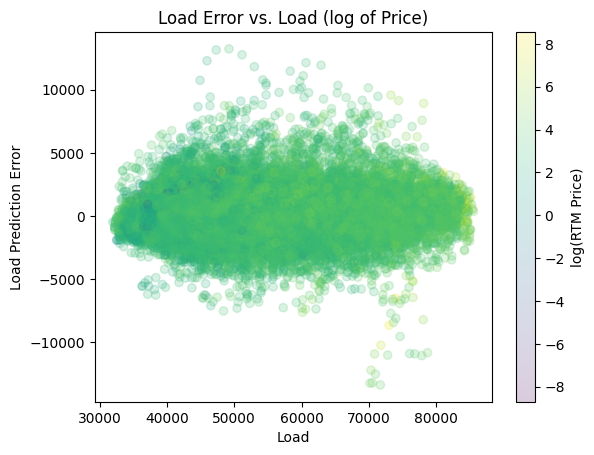

In [6]:
# error vs. load (color log price)

sc = plt.scatter(df['actual_load'], df['load_forecast_error'], alpha=0.2, c=np.log(df['avg_rtm_price']))
plt.colorbar(sc, label='log(RTM Price)')
plt.title('Load Error vs. Load (log of Price)')
plt.ylabel('Load Prediction Error')
plt.xlabel('Load')

In [7]:
df.describe()

,avg_rtm_price,datetime,actual_load,load_forecast_error,abs_load_error
count,33675.000000,33675,33621.000000,33621.000000,33621.000000
mean,43.723182,2023-12-31 06:54:21.755011072,52561.024460,95.842139,1266.277318
min,-31.813667,2022-02-01 01:00:00,31955.060547,-13370.523438,0.089844
25%,17.589167,2023-01-15 20:30:00,44150.703125,-926.757813,447.515625
50%,25.162000,2023-12-30 11:00:00,49910.113281,-14.605469,952.285156
75%,41.769583,2024-12-15 04:30:00,59325.816406,981.730469,1702.867188
max,5173.338667,2025-12-01 00:00:00,85558.984375,13228.574219,13370.523438
std,150.171619,NaN,11191.114070,1741.452574,1199.306931


/usr/local/lib/python3.10/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Text(0.5, 0, 'Load')

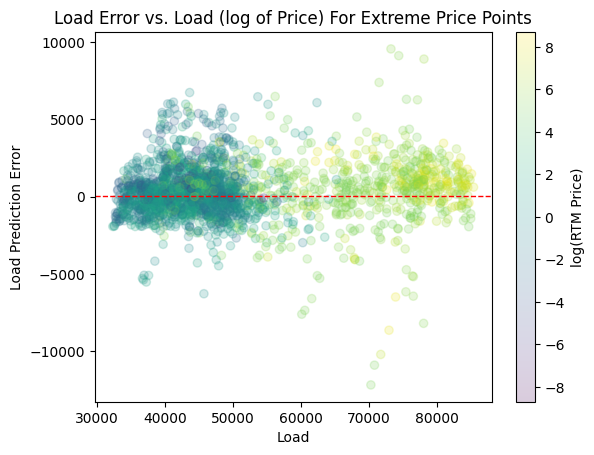

In [8]:
# filter to extreme prices
# error vs. load (color log price)

df_filter = df[(df['avg_rtm_price'] < 5) | (df['avg_rtm_price'] > 150)]

colors = np.sign(df_filter['avg_rtm_price']) * np.log(abs(df_filter['avg_rtm_price']))
sc = plt.scatter(df_filter['actual_load'], df_filter['load_forecast_error'], alpha=0.2, c=colors)
plt.colorbar(sc, label='log(RTM Price)')
plt.axhline(y=15, color='r', linestyle='--', linewidth=1)
plt.title('Load Error vs. Load (log of Price) For Extreme Price Points')
plt.ylabel('Load Prediction Error')
plt.xlabel('Load')

In [9]:
df_extreme = df_filter[(df_filter['avg_rtm_price'] > 150) & (df_filter['datetime'].dt.year == 2023)]
df_extreme['datetime'].dt.date.unique()

array([datetime.date(2023, 1, 30), datetime.date(2023, 2, 2),
       datetime.date(2023, 3, 9), datetime.date(2023, 3, 19),
       datetime.date(2023, 3, 25), datetime.date(2023, 3, 26),
       datetime.date(2023, 3, 27), datetime.date(2023, 4, 21),
       datetime.date(2023, 5, 1), datetime.date(2023, 5, 4),
       datetime.date(2023, 5, 5), datetime.date(2023, 5, 11),
       datetime.date(2023, 5, 24), datetime.date(2023, 6, 2),
       datetime.date(2023, 6, 10), datetime.date(2023, 6, 14),
       datetime.date(2023, 6, 16), datetime.date(2023, 6, 18),
       datetime.date(2023, 6, 19), datetime.date(2023, 6, 20),
       datetime.date(2023, 6, 21), datetime.date(2023, 7, 3),
       datetime.date(2023, 7, 10), datetime.date(2023, 7, 11),
       datetime.date(2023, 7, 12), datetime.date(2023, 7, 30),
       datetime.date(2023, 7, 31), datetime.date(2023, 8, 1),
       datetime.date(2023, 8, 2), datetime.date(2023, 8, 3),
       datetime.date(2023, 8, 4), datetime.date(2023, 8, 6),
    

In [10]:
## analysis of 2023-08 load forecast

Text(0.5, 0.98, 'Load Forecast Error vs. Actual Load Over Year (Log of Price)')

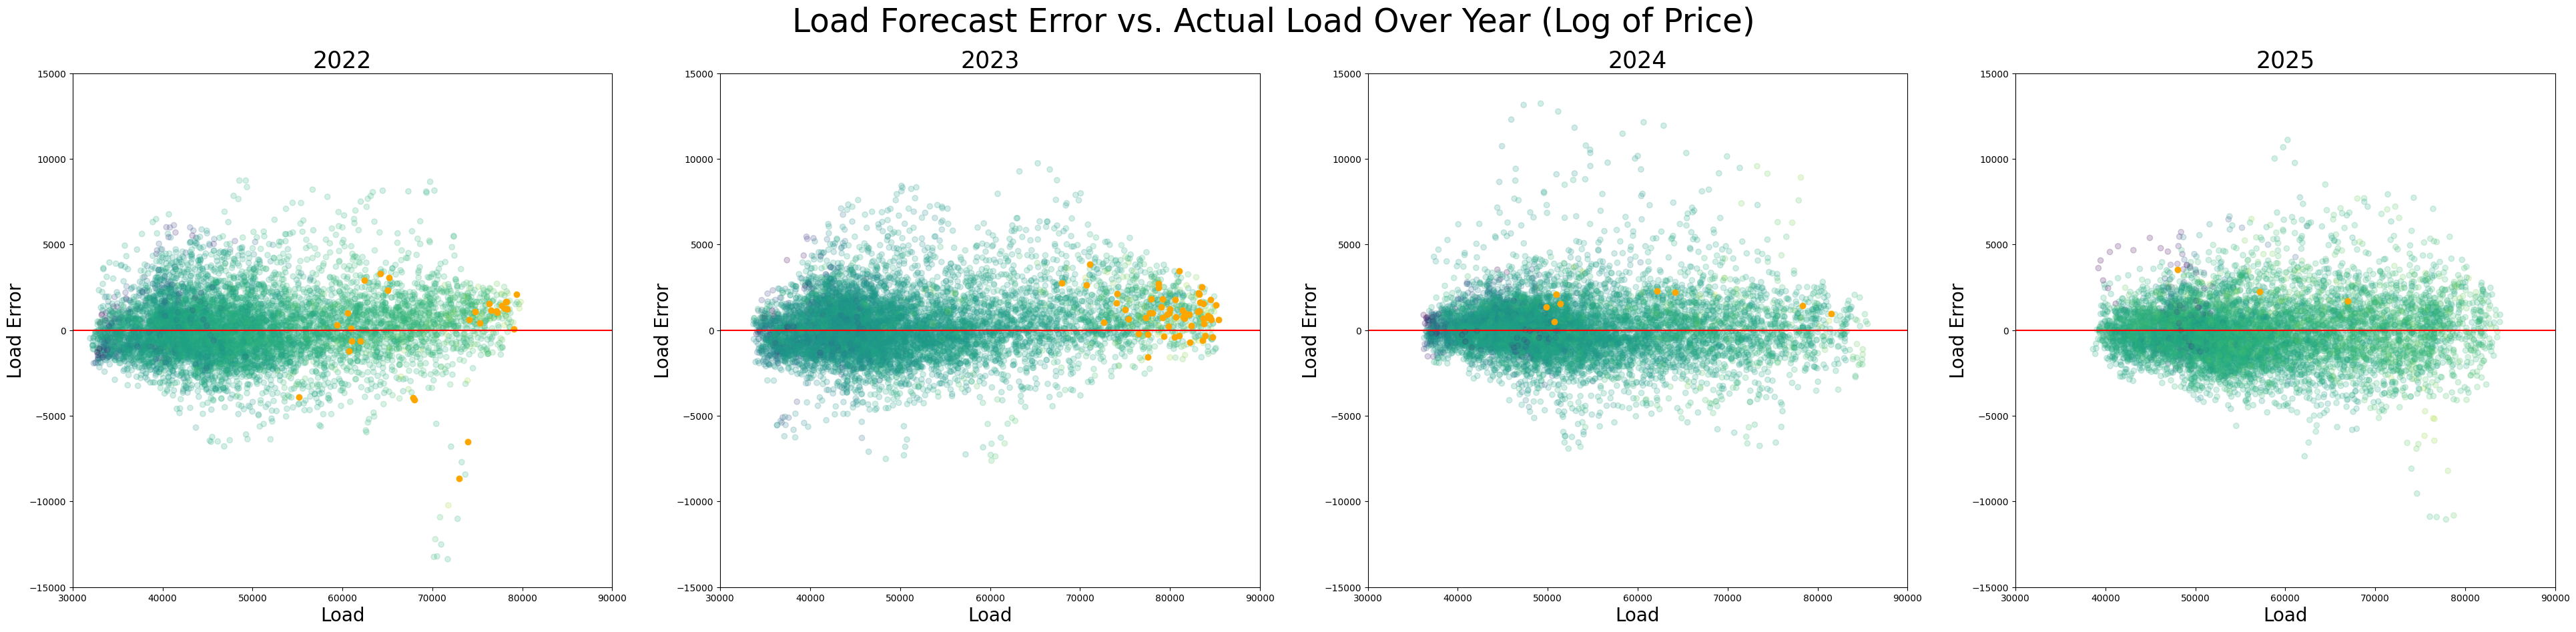

In [11]:
years = [2022, 2023, 2024, 2025]

fig, axes = plt.subplots(1, 4, figsize=(48, 10))
axes = axes.flatten()

for ax, year in zip(axes, years):
    year_data = df[df['datetime'].dt.year == year]
    color_vals = np.sign(year_data['avg_rtm_price']) * np.log1p(np.abs(year_data['avg_rtm_price']))
    ax.scatter(year_data['actual_load'], year_data['load_forecast_error'], alpha=0.2, c=color_vals)
    
    # highlight extreme values
    high_prices = year_data[color_vals > 7]
    ax.scatter(high_prices['actual_load'], high_prices['load_forecast_error'], c='orange')
    ax.hlines(0, 30000, 90000, colors='red')
    ax.set_title(year, fontsize=25)
    ax.set_ylim(-15000, 15000)
    ax.set_xlim(30000, 90000)
    ax.set_ylabel('Load Error', fontsize=20)
    ax.set_xlabel('Load', fontsize=20)

fig.suptitle('Load Forecast Error vs. Actual Load Over Year (Log of Price)', fontsize=35)